В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
sequence_length = 365 * 5

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['DOT', 'ETH', 'XLM', 'XRP', 'XMR', 'ADA', 'LINK', 'BTC', 'SOL', 'DOGE']

In [6]:
# strategy={"extra_buy_amount": 500}
strategy={}

04:20:30 - cmdstanpy - INFO - Chain [1] start processing
04:20:30 - cmdstanpy - INFO - Chain [1] done processing


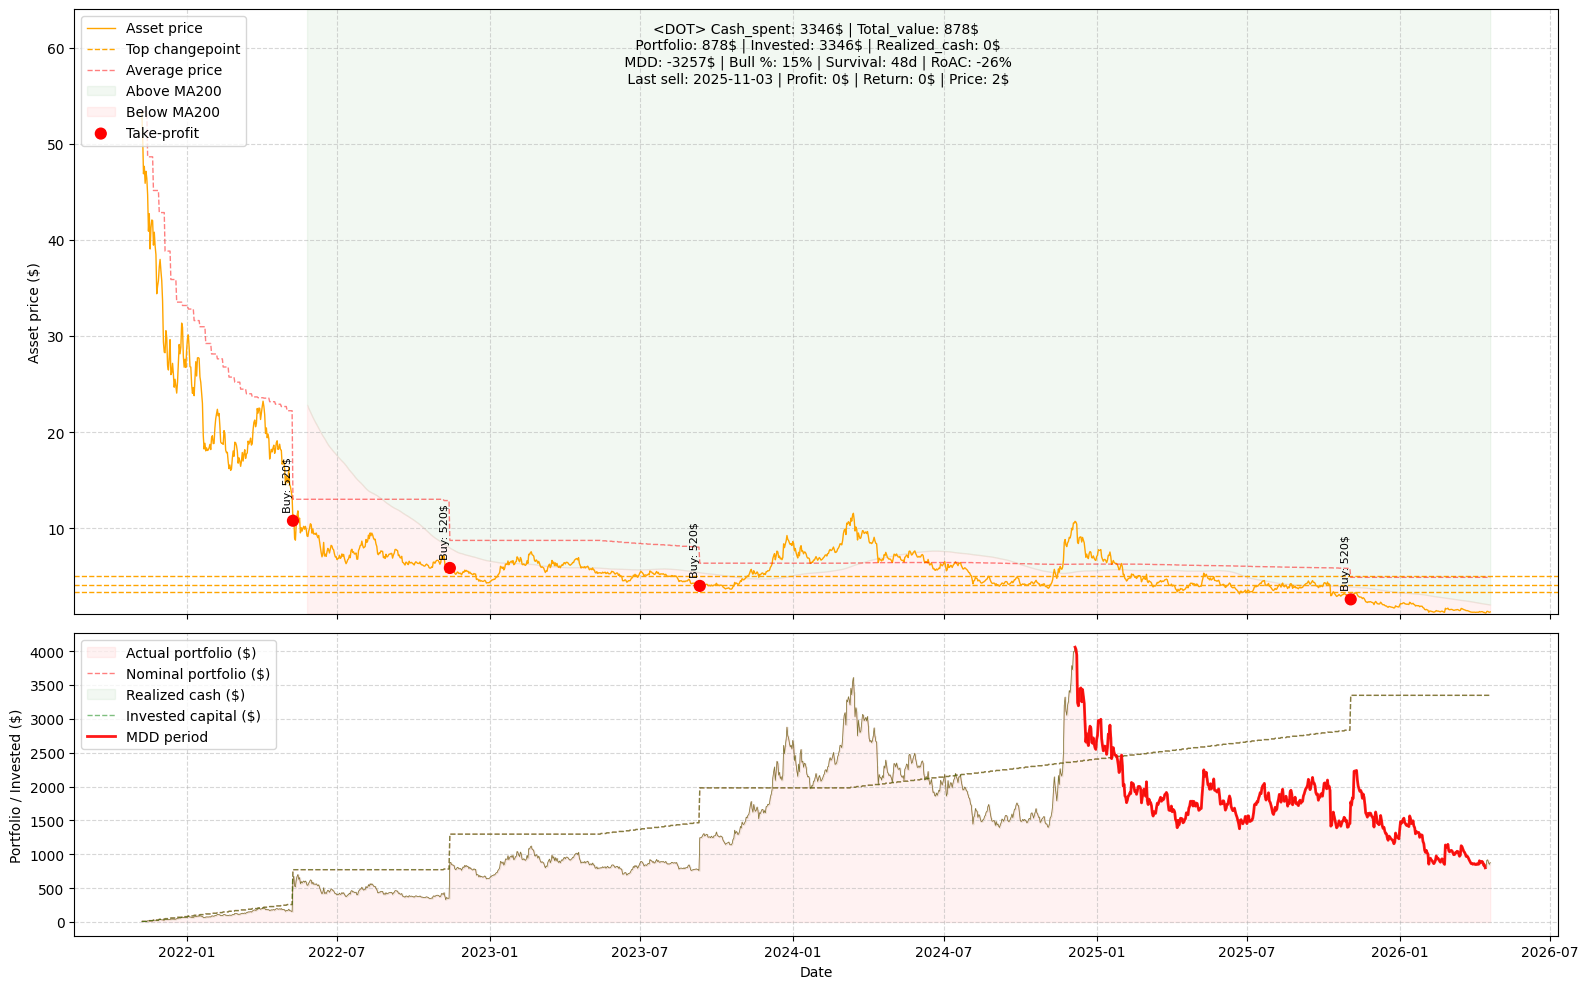

04:20:31 - cmdstanpy - INFO - Chain [1] start processing
04:20:31 - cmdstanpy - INFO - Chain [1] done processing


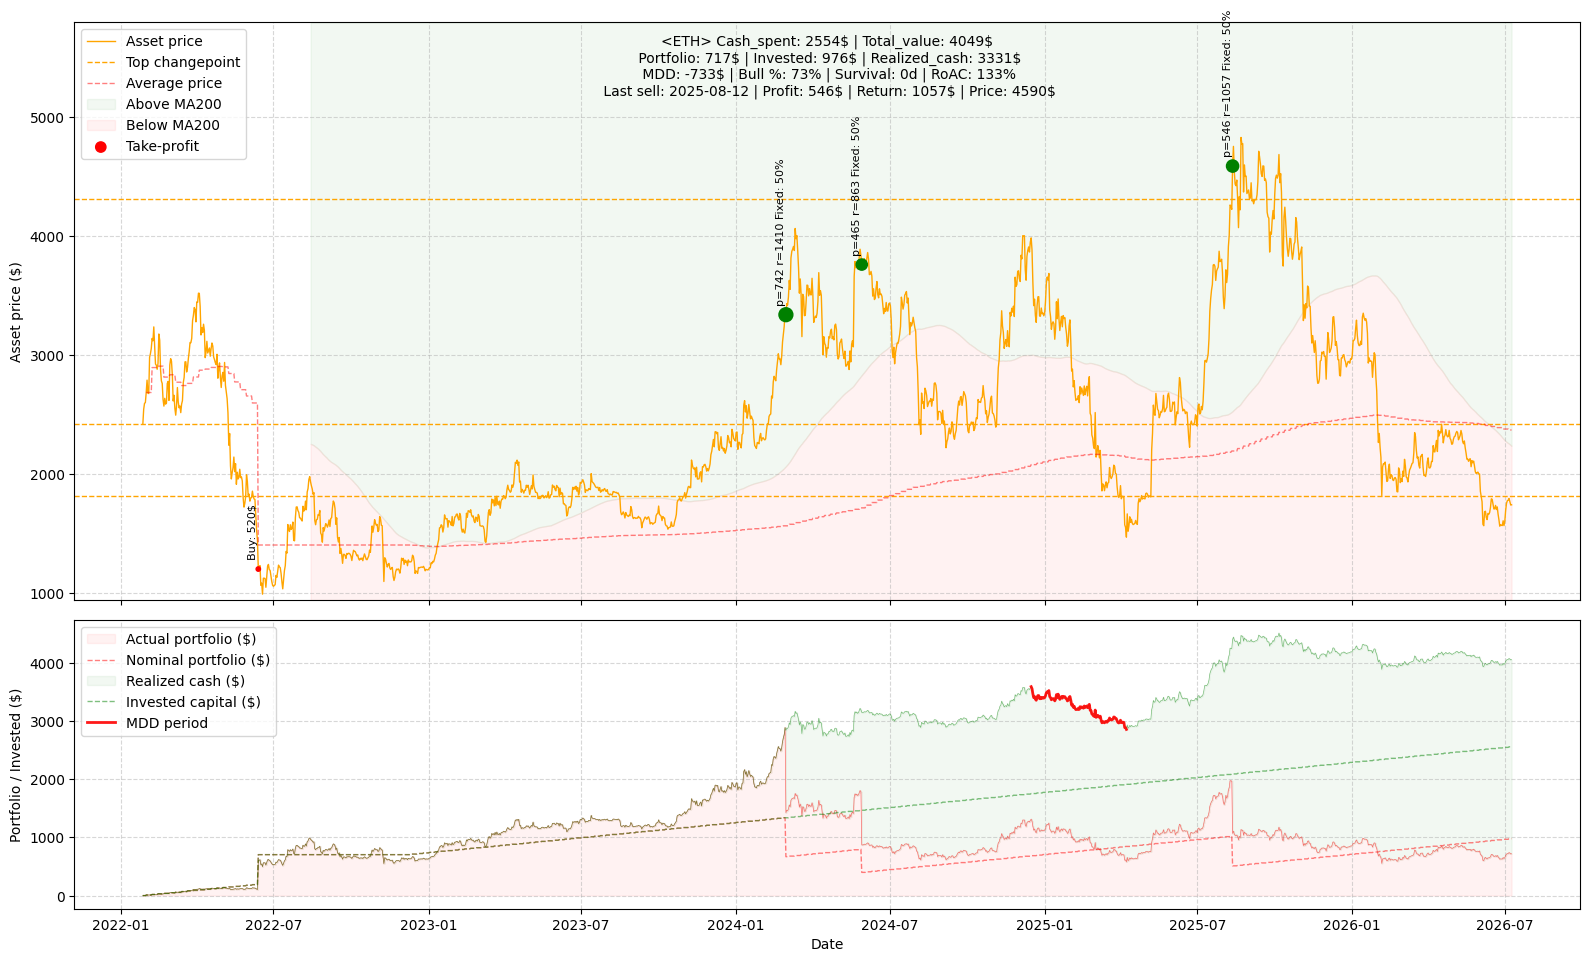

04:20:32 - cmdstanpy - INFO - Chain [1] start processing
04:20:32 - cmdstanpy - INFO - Chain [1] done processing


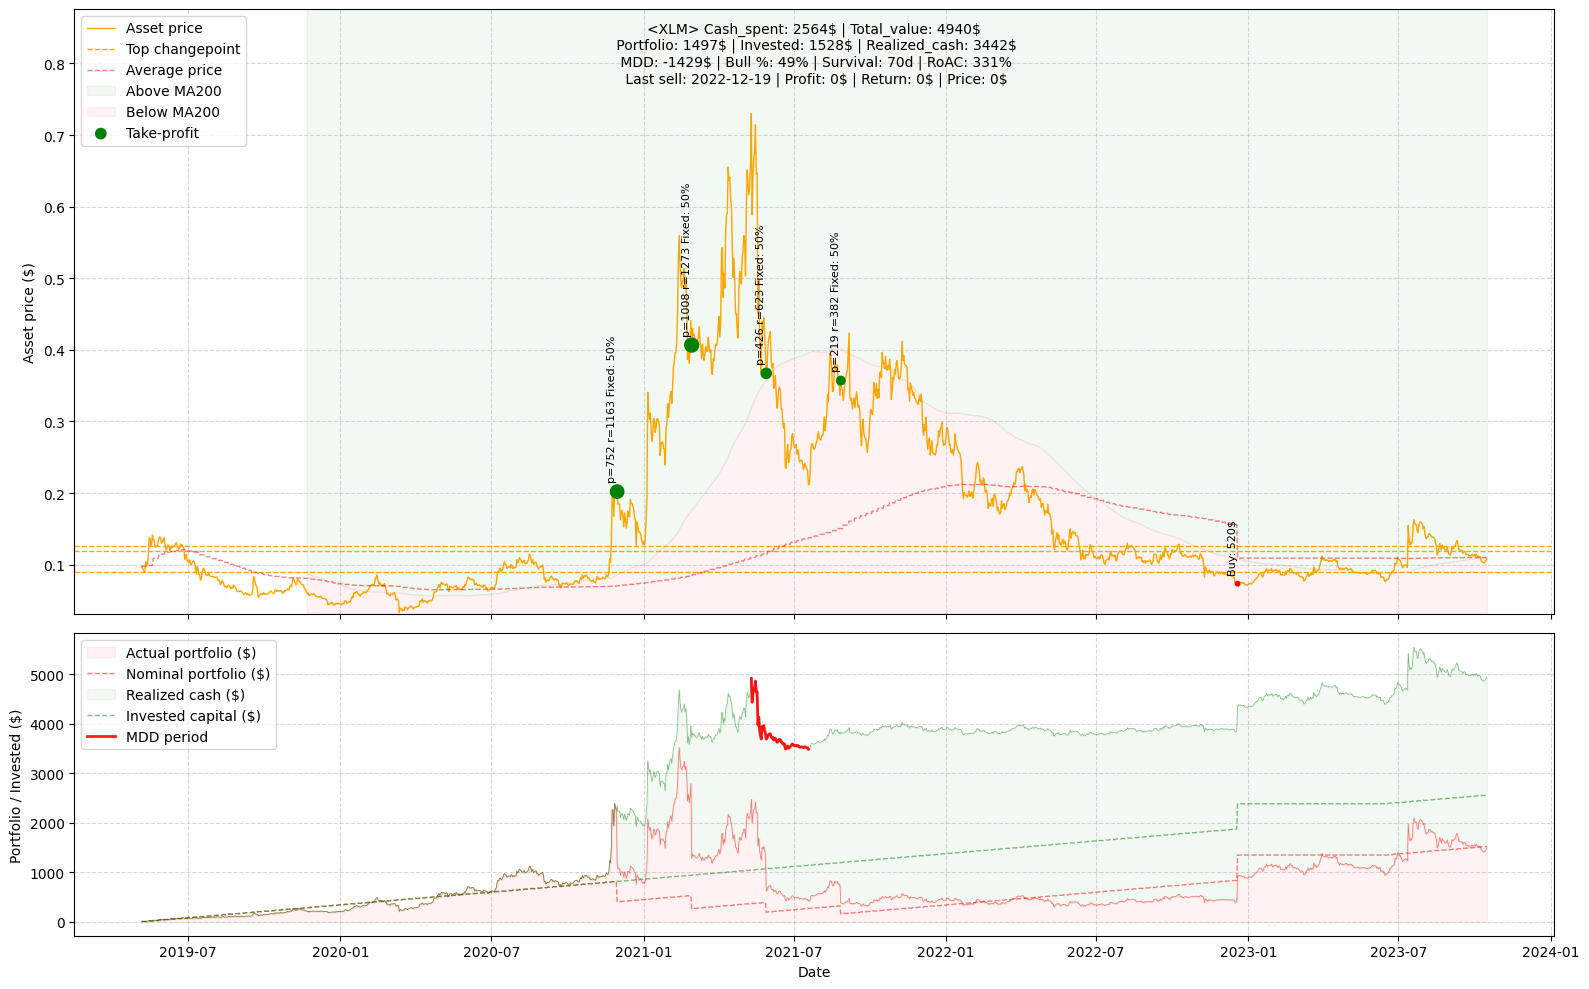

04:20:32 - cmdstanpy - INFO - Chain [1] start processing
04:20:32 - cmdstanpy - INFO - Chain [1] done processing


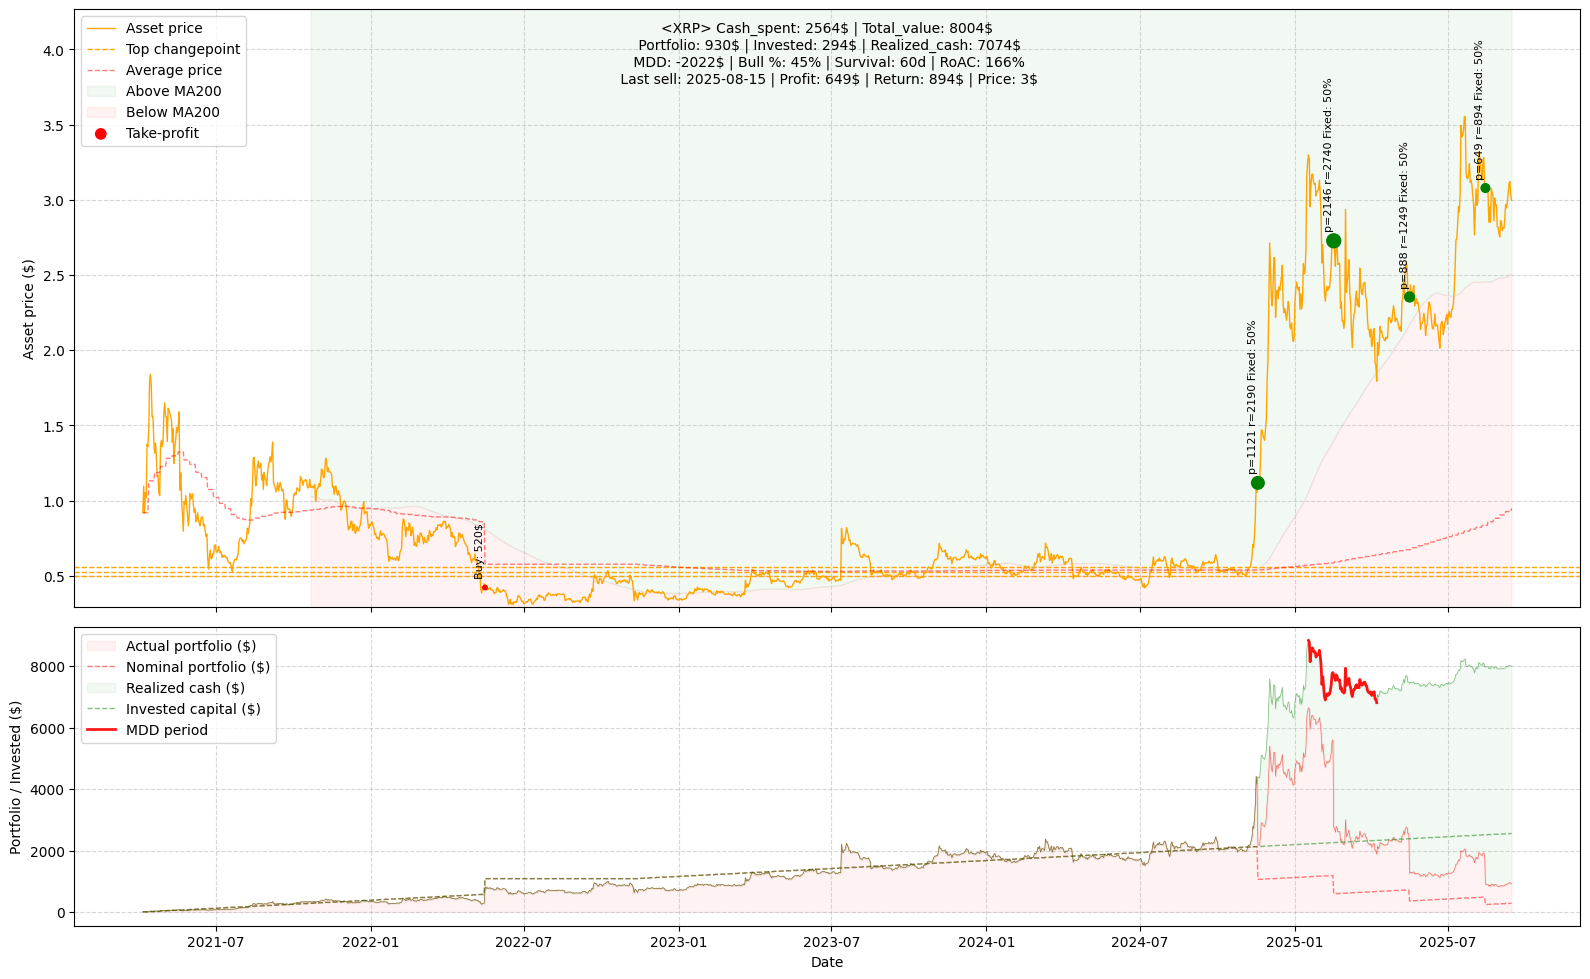

04:20:33 - cmdstanpy - INFO - Chain [1] start processing
04:20:33 - cmdstanpy - INFO - Chain [1] done processing


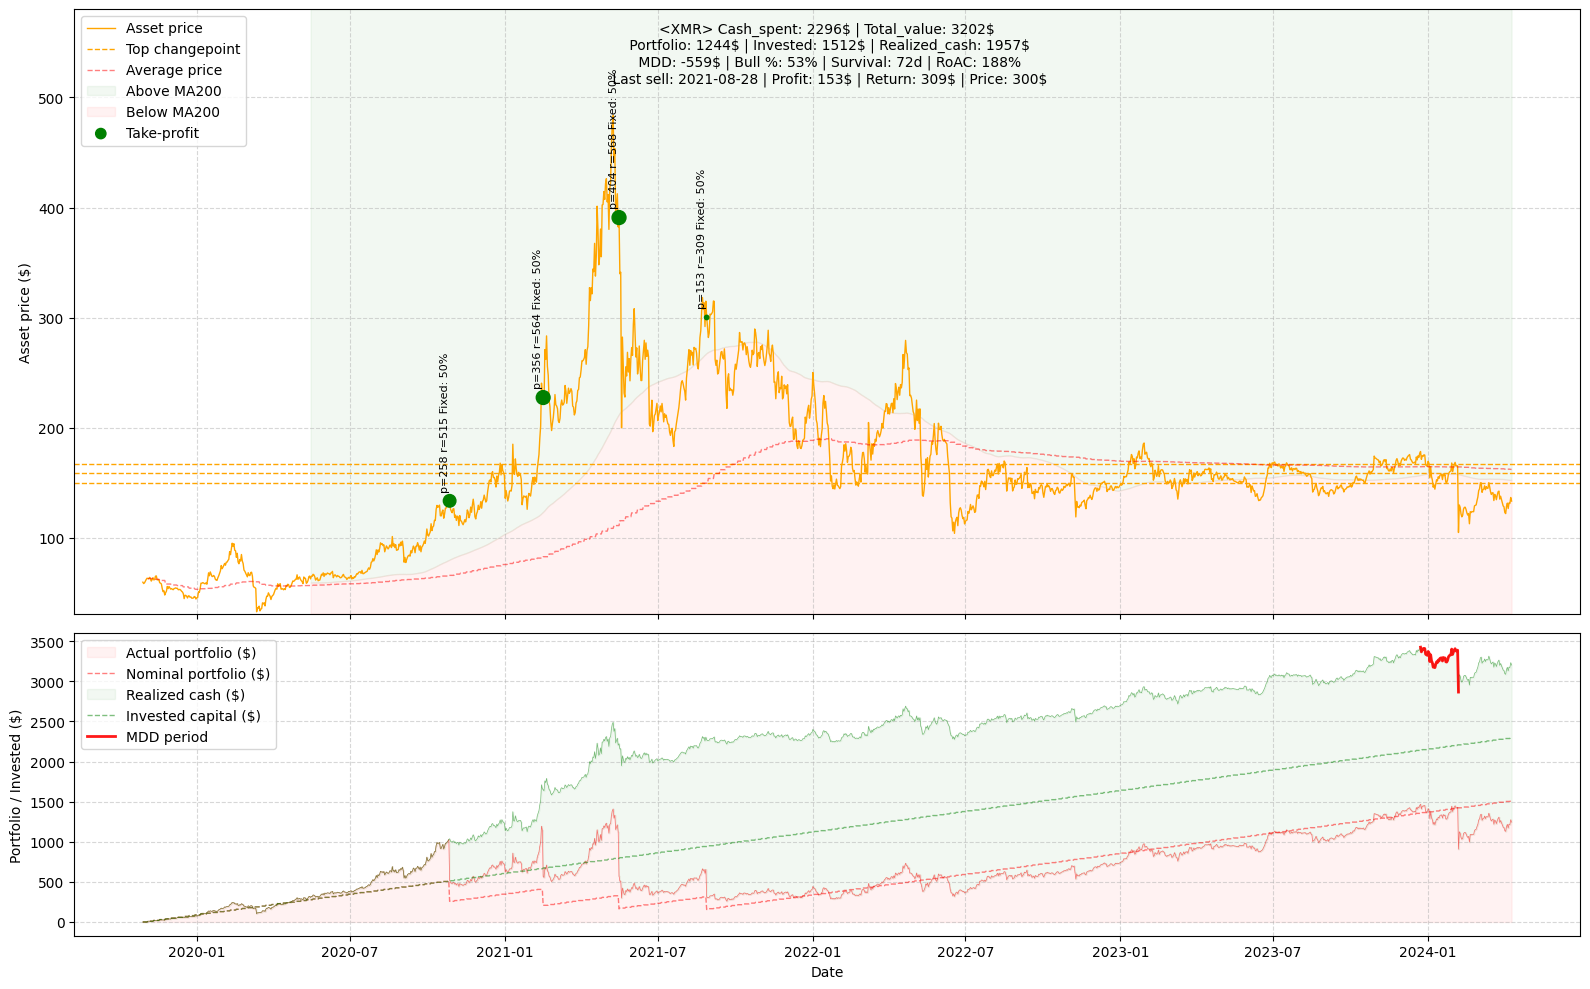

04:20:33 - cmdstanpy - INFO - Chain [1] start processing
04:20:34 - cmdstanpy - INFO - Chain [1] done processing


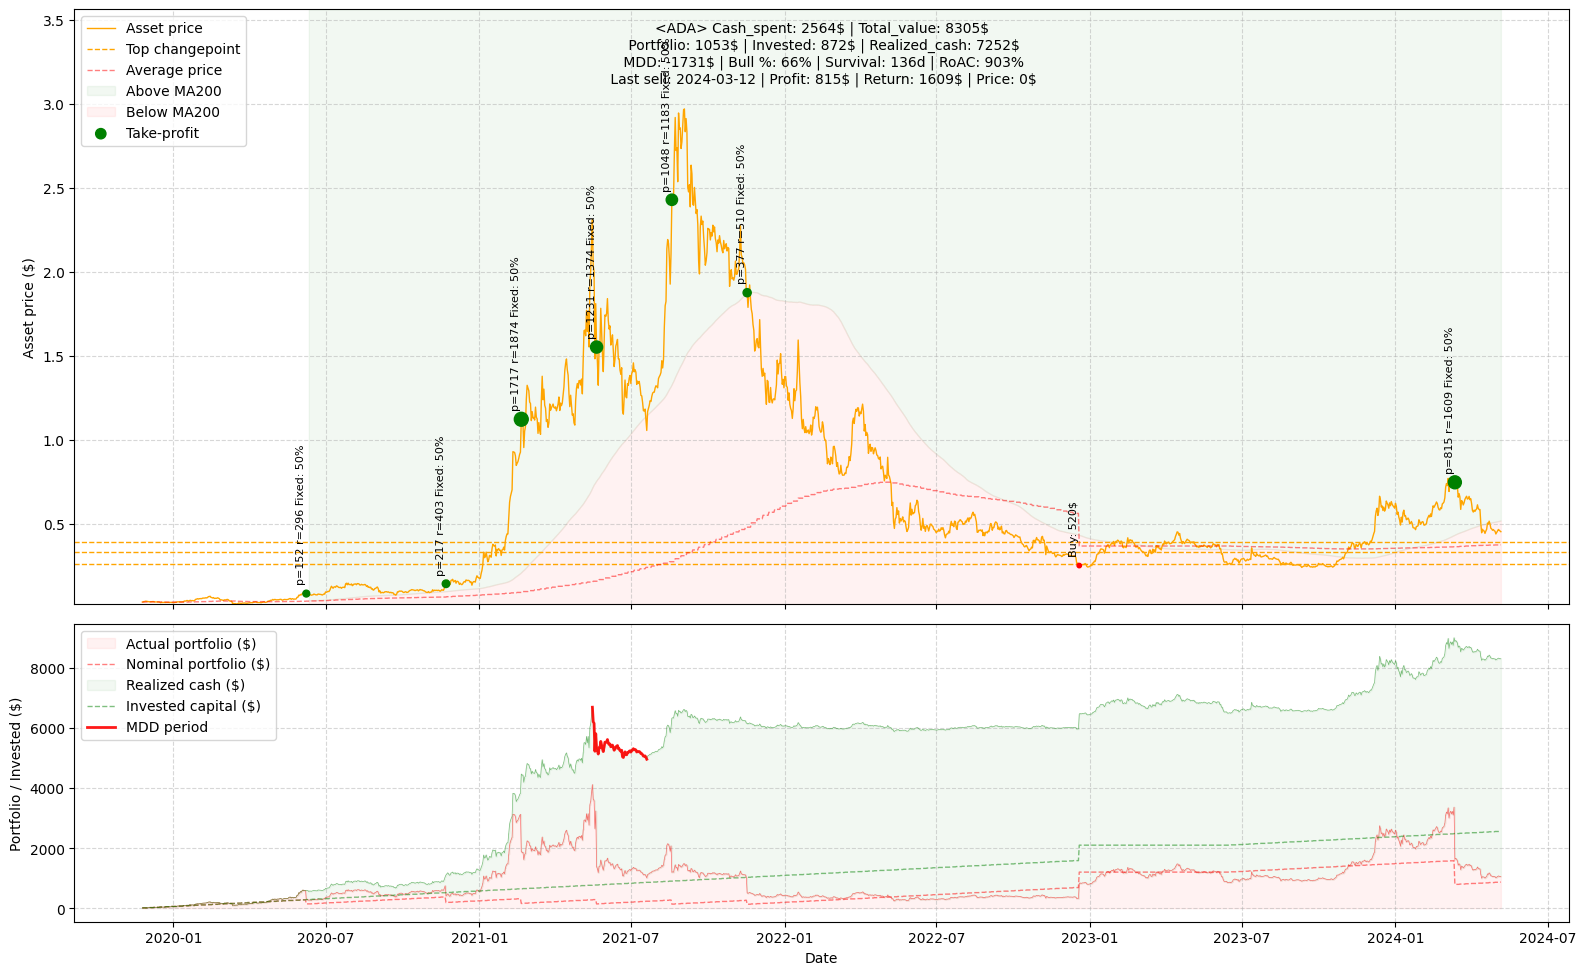

04:20:34 - cmdstanpy - INFO - Chain [1] start processing
04:20:34 - cmdstanpy - INFO - Chain [1] done processing


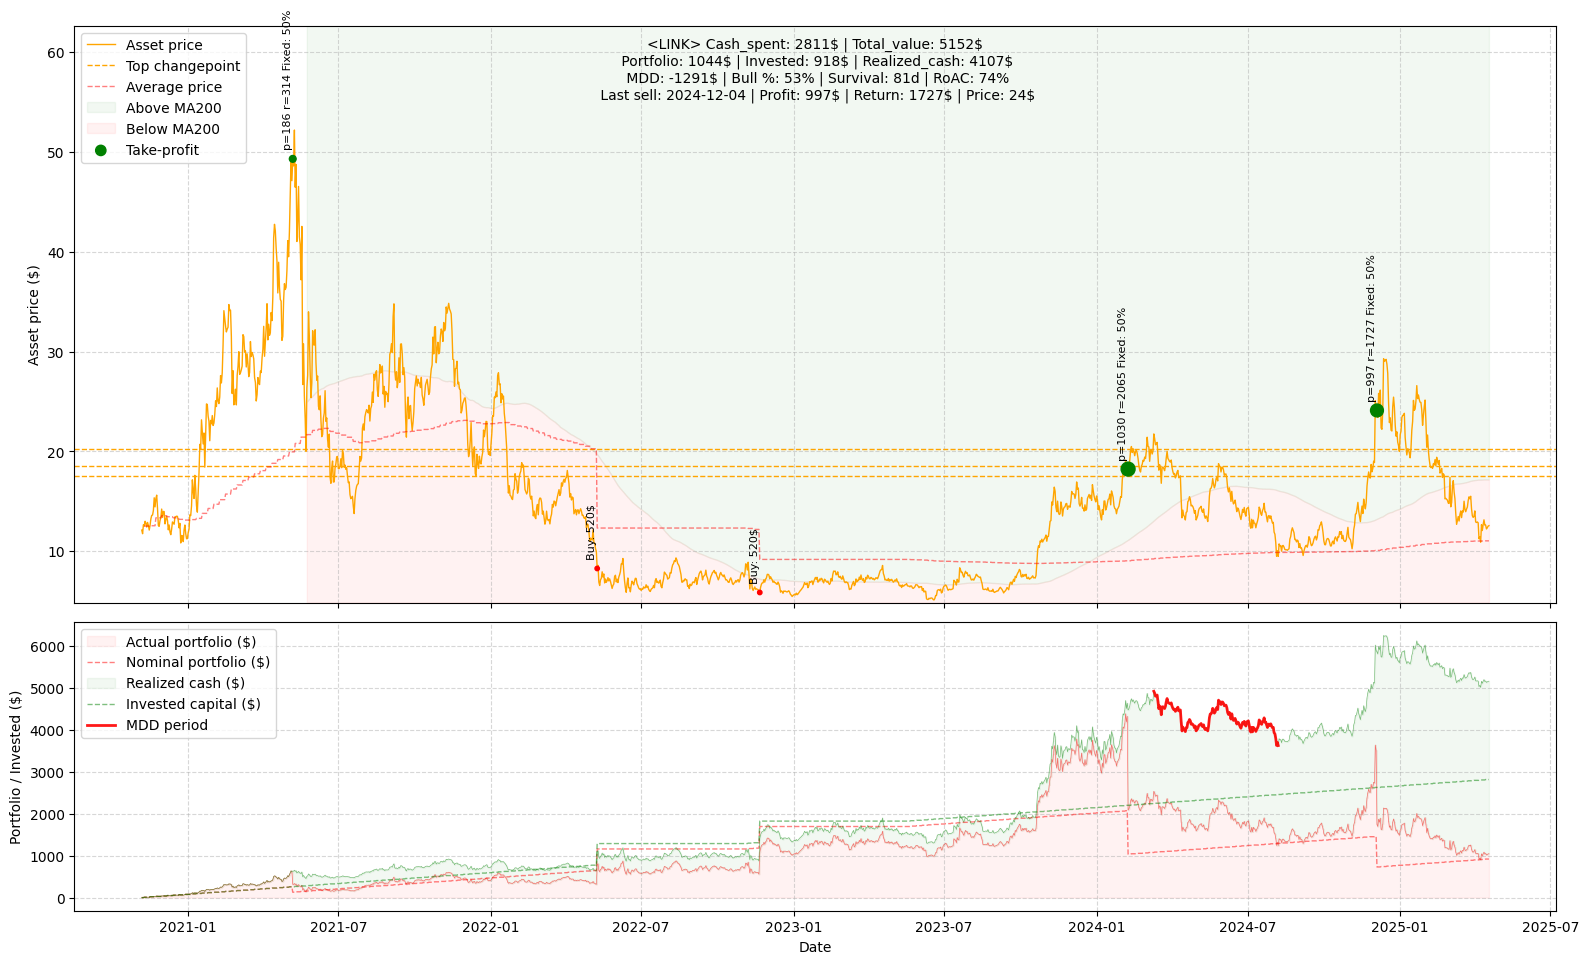

04:20:35 - cmdstanpy - INFO - Chain [1] start processing
04:20:35 - cmdstanpy - INFO - Chain [1] done processing


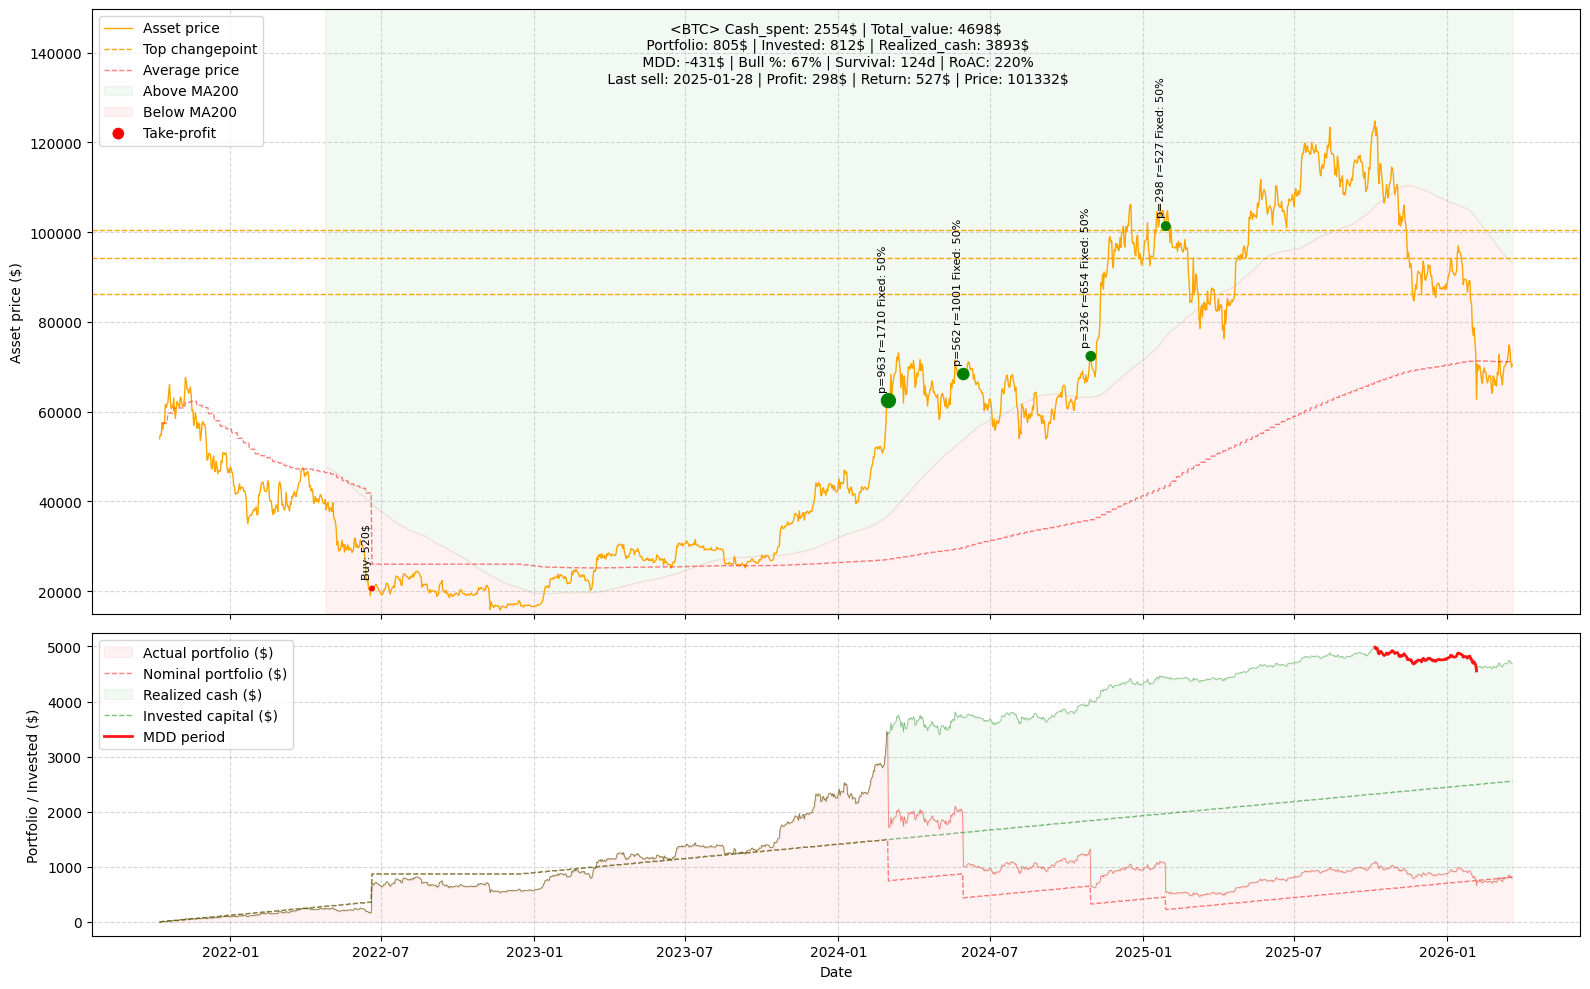

04:20:35 - cmdstanpy - INFO - Chain [1] start processing
04:20:36 - cmdstanpy - INFO - Chain [1] done processing


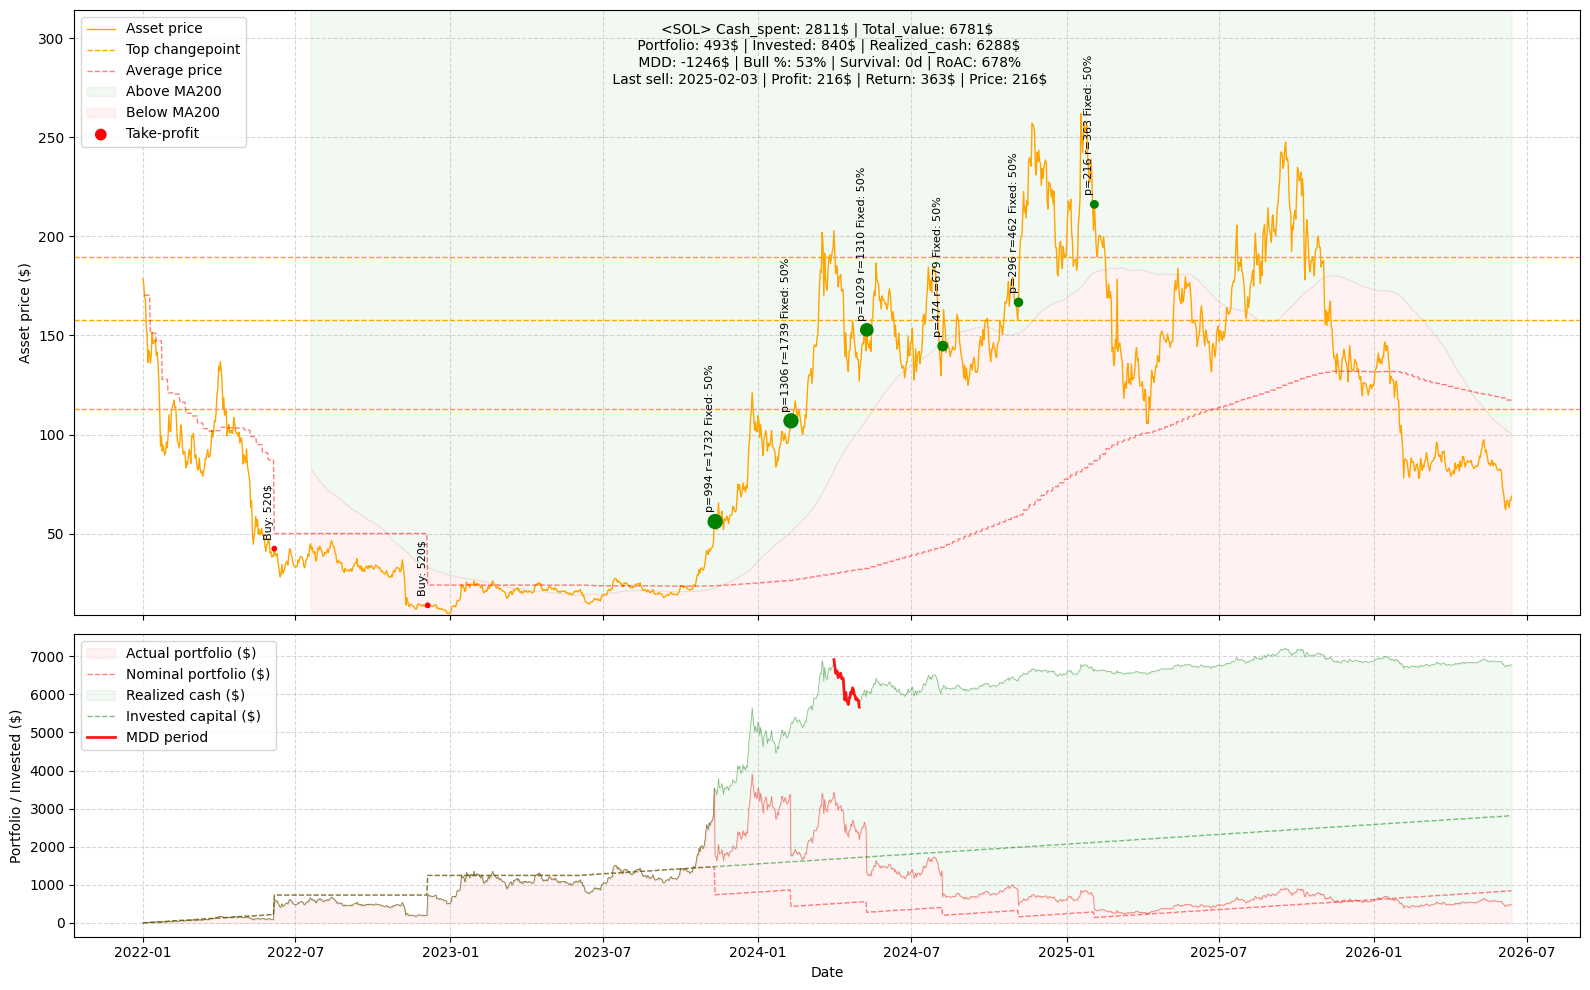

04:20:36 - cmdstanpy - INFO - Chain [1] start processing
04:20:36 - cmdstanpy - INFO - Chain [1] done processing


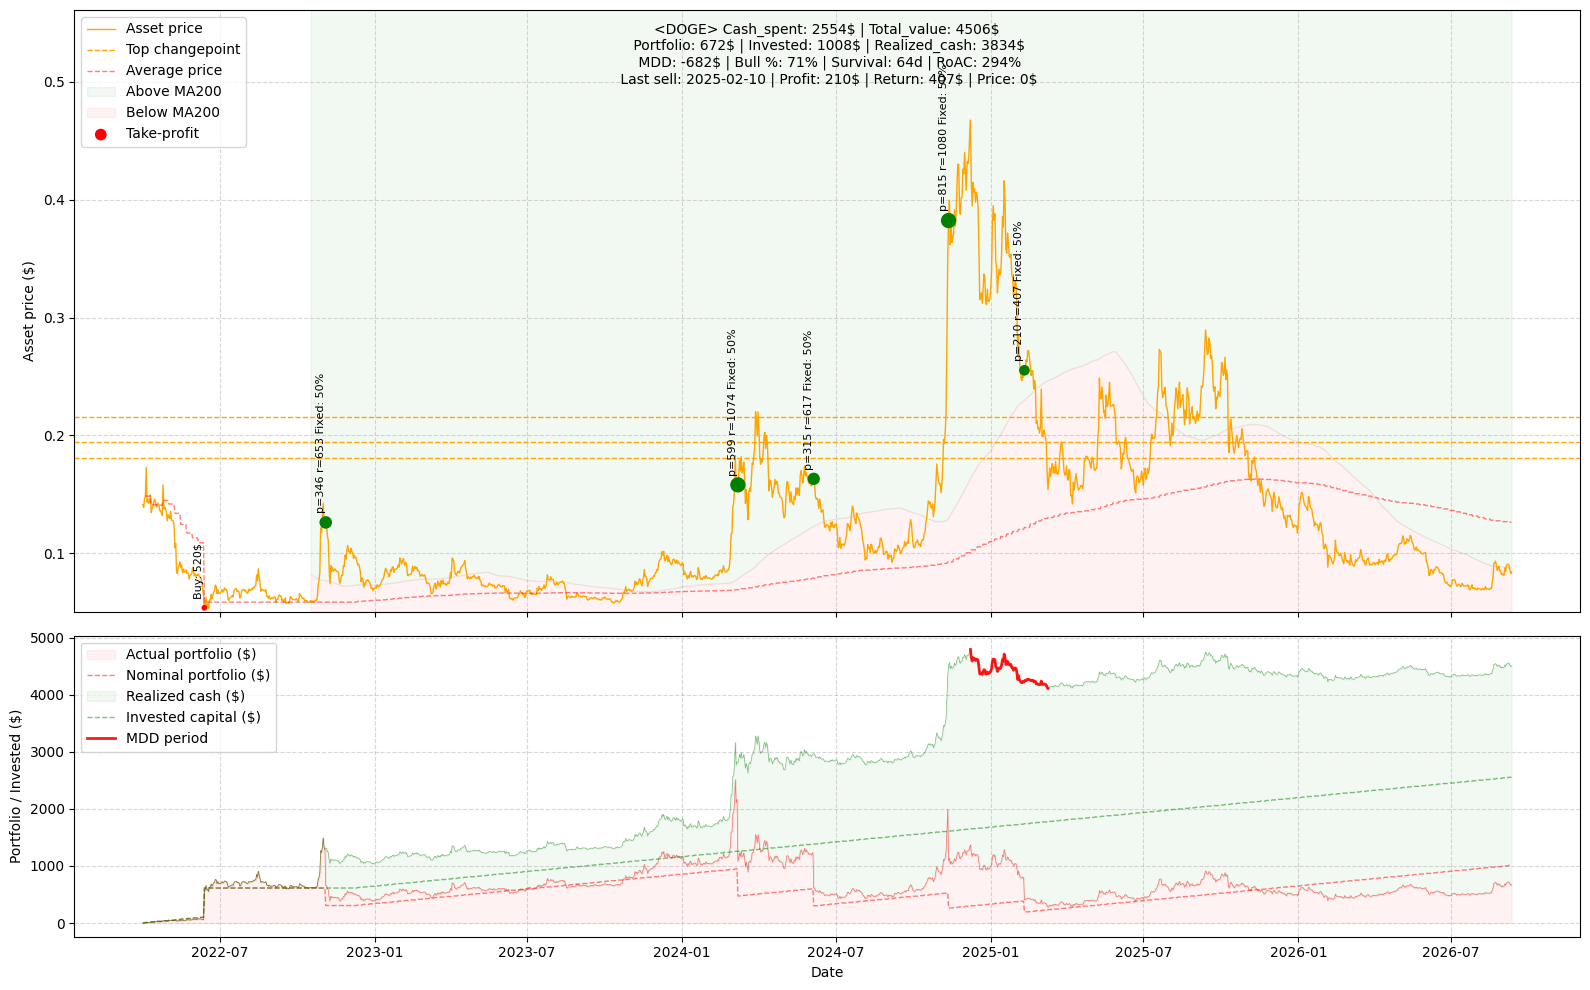

Total invested: $26618.00
Total return: $41178.00
Total value: $50515.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2022-04-01,0.141315,0.000000,0.0000,0.0,0.0,0.0,0.00000,,0.000000,NaN,0.000000
2022-04-02,0.138913,0.000000,0.0000,0.0,0.0,0.0,0.00000,,0.000000,NaN,0.000000
2022-04-03,0.146453,0.000000,0.0000,0.0,0.0,0.0,0.00000,,0.000000,NaN,0.000000
2022-04-04,0.148591,66.625840,9.9000,9.9,0.0,0.0,0.00000,,9.900000,0.148591,9.900000
2022-04-05,0.172907,66.625840,9.9000,9.9,0.0,0.0,0.00000,,11.520074,0.148591,11.520074
...,...,...,...,...,...,...,...,...,...,...,...
2026-09-07,0.090627,7976.419191,1008.5625,2554.2,0.0,0.0,3834.22799,,722.878940,0.126443,4557.106930
2026-09-08,0.089994,7976.419191,1008.5625,2554.2,0.0,0.0,3834.22799,,717.829856,0.126443,4552.057846
2026-09-09,0.086163,7976.419191,1008.5625,2554.2,0.0,0.0,3834.22799,,687.272201,0.126443,4521.500191


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(1622)

In [10]:
metrics

{'Target': 'DOGE',
 'Cash_spent': 2554,
 'Realized_cash': 3834,
 'Portfolio': 672,
 'Invested': 1008,
 'Total_value': 4506,
 'Bull_history': 71,
 'Avg_price': np.float64(0.12644301607442515),
 'Num_take_profits': 6,
 'MDD': -682,
 'MA200_survival_days': 63.75,
 'RoAC': 294}